# Inferencia estadística

**Sesión 06 · Estadística II**

La **inferencia estadística** estudia qué podemos afirmar sobre una *población* a partir de una *muestra* y, sobre todo, con qué grado de incertidumbre. Sus resultados habituales son:

+ **estimaciones puntuales**: el valor que mejor aproxima un parámetro de interés;
+ **intervalos de confianza**: un rango de valores plausibles para ese parámetro;
+ **contrastes de hipótesis**: la decisión de rechazar, o no, una hipótesis a la vista de los datos.

En esta sesión trabajamos con el paradigma **frecuentista**, que razona sobre lo **que ocurriría si repitiéramos muchas veces el muestreo de la población**. 

Toda inferencia se apoya en **supuestos** sobre el proceso de muestreo (por ejemplo, que las observaciones son independientes): las conclusiones solo son válidas si esos supuestos se cumplen.

**Contenido**

1. Punto de partida: un efecto aparente
2. Conceptos básicos
3. Distribución muestral y error estándar
4. *Bootstrap*: estimar la variabilidad por remuestreo
5. Ejercicio: accidentes de tráfico en Barcelona
6. Intervalos de confianza
7. Contraste de hipótesis y significación estadística
8. Conclusiones

## 1. Punto de partida: un efecto aparente

Al explorar los datos de la *National Survey of Family Growth* (NSFG) observamos un **efecto aparente** que parece respaldar una hipótesis: *la duración media del embarazo de los primeros hijos es mayor que la de los demás hijos*.

Antes de darlo por bueno, quedan tres preguntas por responder:

1. ¿Cómo calcular la probabilidad de que el efecto se deba **al azar**, es decir, a la muestra concreta que hemos obtenido?
2. ¿El resultado es **estadísticamente significativo**?
3. ¿El resultado es **relevante** en la práctica?

A lo largo del notebook construiremos las herramientas para responderlas y volveremos a ellas en las conclusiones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use('ggplot')
rng = np.random.default_rng(2026)   # semilla fija: los resultados son reproducibles

In [2]:
# Datos de embarazos de la NSFG (2002)
nsfg = pd.read_fwf(
    'files/2002FemPreg.dat',
    colspecs=[(0, 12), (274, 276), (276, 277), (277, 279), (422, 440)],
    names=['caseid', 'prglength', 'outcome', 'birthord', 'finalwgt'],
).fillna({'birthord': 0})

nacidos_vivos = nsfg[nsfg.outcome == 1]                                     # outcome == 1: nacido vivo
primeros = nacidos_vivos.loc[nacidos_vivos.birthord == 1, 'prglength']      # duración en semanas
otros = nacidos_vivos.loc[nacidos_vivos.birthord >= 2, 'prglength']

resumen = pd.DataFrame({
    'n': [len(primeros), len(otros)],
    'media (semanas)': [primeros.mean(), otros.mean()],
    'desv. estándar': [primeros.std(), otros.std()],
}, index=['Primeros hijos', 'Demás hijos'])
resumen.round(3)

,n,media (semanas),desv. estándar
Primeros hijos,4413,38.601,2.792
Demás hijos,4735,38.523,2.616


In [3]:
diferencia_obs = primeros.mean() - otros.mean()
print(f'Diferencia de medias: {diferencia_obs:.3f} semanas (≈ {diferencia_obs * 7 * 24:.0f} horas)')

Diferencia de medias: 0.078 semanas (≈ 13 horas)


Los primeros hijos nacen, en promedio, unas 0,08 semanas más tarde. ¿Es una diferencia real o fruto del azar? 

Para responder necesitamos saber **cuánto varían las estimaciones de una muestra a otra**.

## 2. Conceptos básicos

+ **Población**: el conjunto completo de individuos sobre el que queremos sacar conclusiones (por ejemplo, todos los nacimientos de EE. UU.).
+ **Muestra**: el subconjunto de la población que realmente observamos (por ejemplo, los nacimientos registrados en la NSFG).
+ **Parámetro**: un valor numérico que describe la población, como la media poblacional $\mu$. Es **fijo**, pero casi siempre desconocido.
+ **Estadístico**: cualquier valor calculado a partir de la muestra, como la media muestral $\bar{x}$. Cuando lo usamos para aproximar un parámetro lo llamamos **estimador**, y el valor concreto que obtenemos con nuestra muestra es una **estimación puntual**.

| | Parámetro (población) | Estadístico (muestra) |
|---|:---:|:---:|
| Media | $\mu$ | $\bar{x}$ |
| Desviación estándar | $\sigma$ | $s$ |
| Proporción | $p$ | $\hat{p}$ |

La idea clave es la **variabilidad muestral**: un estadístico cambia de una muestra a otra. Una estimación puntual estará cerca del parámetro (tanto más cuantos más datos tengamos), pero casi nunca coincidirá con él. Hacer inferencia es **cuantificar esa variabilidad** para saber cuánto podemos fiarnos de una estimación.

> **Un recurso didáctico.** Para *ver* la variabilidad muestral necesitaríamos conocer la población, cosa que en la realidad nunca ocurre. Por eso, en algunas simulaciones trataremos los 4413 primeros hijos de la NSFG **como si fueran la población completa** y extraeremos muestras de ellos. Lo indicaremos siempre de forma explícita. En el resto del notebook volvemos a la situación real: la NSFG es *una* muestra y no disponemos de nada más.

## 3. Distribución muestral y error estándar

### 3.1 La distribución muestral de la media

Queremos estimar la media poblacional $\mu$ de la duración del embarazo. El estimador natural es la media muestral $\bar{x}$. Pero ¿cuánto cambiaría $\bar{x}$ si hubiéramos obtenido otra muestra?

Como (de momento) suponemos que disponemos de la población, podemos comprobarlo directamente: extraemos 10 000 muestras de $n = 1000$ observaciones y calculamos la media de cada una.

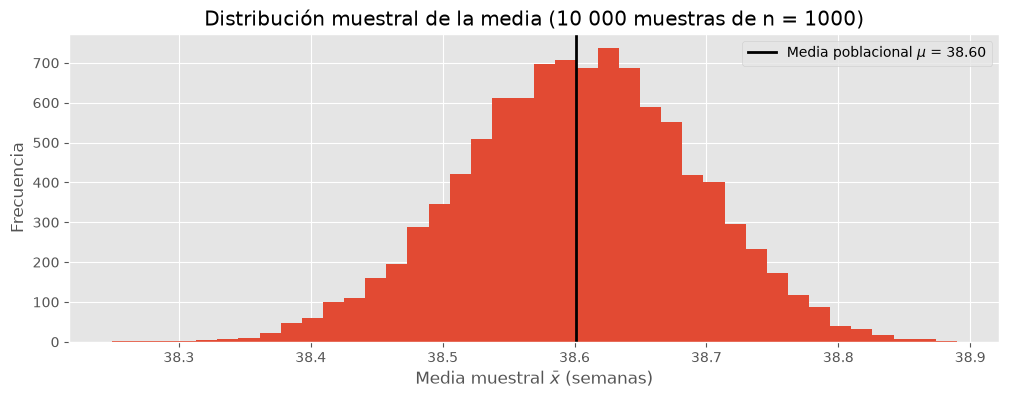

In [4]:
poblacion = primeros.to_numpy()   # recurso didáctico: los primeros hijos hacen de población
mu = poblacion.mean()             # el parámetro (en la práctica, desconocido)

n = 1000                          # observaciones por muestra
n_muestras = 10_000               # número de muestras

medias = np.array([rng.choice(poblacion, size=n).mean() for _ in range(n_muestras)])

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(medias, bins=40)
ax.axvline(mu, color='black', lw=2, label=f'Media poblacional $\\mu$ = {mu:.2f}')
ax.set_xlabel('Media muestral $\\bar{x}$ (semanas)')
ax.set_ylabel('Frecuencia')
ax.set_title(f'Distribución muestral de la media (10 000 muestras de n = {n})')
ax.legend()
plt.show()

Este histograma aproxima la **distribución muestral** de la media:

> La **distribución muestral** de un estadístico es la distribución de los valores que toma ese estadístico cuando se calcula sobre todas las posibles muestras de tamaño $n$ de una población.

Conviene pensar que **nuestra estimación puntual es una extracción al azar de esta distribución**. 

Si conociéramos la distribución muestral, podríamos responder con fundamento preguntas como:

+ ¿Cuánta incertidumbre tiene la media muestral?
+ ¿Qué probabilidad hay de obtener una media muestral $\geq x$? Es decir, ¿es plausible un valor concreto?

Es decir, podríamos hacer **afirmaciones cuantitativas sobre la incertidumbre** del estimador puntual. Este concepto es la base de toda la inferencia estadística.

### 3.2 El error estándar

La medida más útil de la anchura de una distribución muestral es su desviación estándar:

> El **error estándar** ($SE$) de un estimador es la desviación estándar de su distribución muestral. Mide cuánto varía la estimación de una muestra a otra, es decir, su **precisión**.

En la práctica no tenemos la población y no podemos simular la distribución muestral. Sin embargo, **para la media** la teoría nos da el resultado: si tenemos $n$ observaciones independientes de una población con desviación estándar $\sigma$,

$$ SE_{\bar{x}} = \frac{\sigma}{\sqrt{n}} $$

+ Cuanto mayor es la muestra, menor es el error estándar y más precisa la estimación (para reducirlo a la mitad hay que cuadruplicar $n$).
+ $\sigma$ también es un parámetro desconocido, así que se sustituye por la desviación estándar muestral $s$: $\widehat{SE}_{\bar{x}} = s/\sqrt{n}$. La aproximación es buena si $n \geq 30$ y la población no es muy asimétrica.

Así podemos estimar el error estándar **a partir de una única muestra**. Comparémoslo con el valor obtenido en la simulación:

In [5]:
muestra = rng.choice(poblacion, size=n)          # la única muestra que tendríamos en la práctica

se_simulado = medias.std()                       # desviación estándar de las 10 000 medias simuladas
se_teorico = poblacion.std() / np.sqrt(n)        # fórmula con la σ poblacional (desconocida en la práctica)
se_estimado = muestra.std(ddof=1) / np.sqrt(n)   # fórmula con la s de una sola muestra

print(f'SE según la simulación:              {se_simulado:.4f}')
print(f'SE teórico (σ de la población):      {se_teorico:.4f}')
print(f'SE estimado (s de una sola muestra): {se_estimado:.4f}')

SE según la simulación:              0.0877
SE teórico (σ de la población):      0.0883
SE estimado (s de una sola muestra): 0.0935


### 3.3 El teorema central del límite

El histograma de la sección 3.1 tiene forma de campana. No es casualidad:

> **Teorema central del límite (TCL).** Si las observaciones son independientes y la muestra es suficientemente grande (regla práctica: $n \geq 30$ y población no muy asimétrica), la distribución muestral de la media es aproximadamente **normal**, centrada en $\mu$ y con desviación estándar $SE$:
> $$ \bar{x} \;\approx\; \mathcal{N}\!\left(\mu,\ \frac{\sigma}{\sqrt{n}}\right) $$

Lo notable es que se cumple **aunque la población no sea normal**. La duración del embarazo, por ejemplo, tiene una larga cola de partos prematuros:

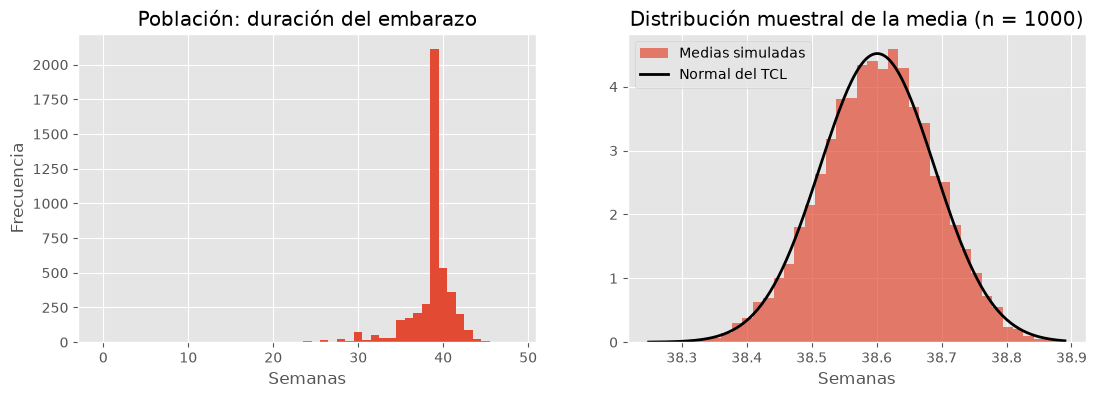

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.hist(poblacion, bins=np.arange(poblacion.min(), poblacion.max() + 2) - 0.5)
ax1.set_title('Población: duración del embarazo')
ax1.set_xlabel('Semanas')
ax1.set_ylabel('Frecuencia')

ax2.hist(medias, bins=40, density=True, alpha=0.7, label='Medias simuladas')
xs = np.linspace(medias.min(), medias.max(), 200)
ax2.plot(xs, stats.norm.pdf(xs, mu, se_teorico), color='black', lw=2, label='Normal del TCL')
ax2.set_title(f'Distribución muestral de la media (n = {n})')
ax2.set_xlabel('Semanas')
ax2.legend()
plt.show()

Una consecuencia que usaremos para construir intervalos de confianza: en una distribución normal, el 95 % de los valores está a menos de **1,96 desviaciones estándar** de la media. Por tanto, aproximadamente el 95 % de las medias muestrales cae en $\mu \pm 1{,}96\, SE$. Lo comprobamos con la simulación:

In [7]:
dentro = np.abs(medias - mu) < 1.96 * se_teorico
print(f'Medias a menos de 1,96 SE de μ: {dentro.mean():.1%}')

Medias a menos de 1,96 SE de μ: 95.0%


### 3.4 ¿Y para otros estadísticos?

Para la media tenemos una fórmula del error estándar y el TCL nos dice la forma de su distribución. Pero a menudo nos interesa la variabilidad de otros estadísticos (la mediana, la desviación estándar, un percentil, un cociente…) para los que **no existe una fórmula sencilla**. Y en un problema real no podemos simular porque **no tenemos acceso a la población**.

La solución computacional a este problema es el *bootstrap*.

## 4. *Bootstrap*: estimar la variabilidad por remuestreo

> El *bootstrap* fue propuesto por Bradley Efron en *Bootstrap methods: another look at the jackknife* (1979), inspirándose en el método *jackknife*.

**La idea.** No podemos extraer nuevas muestras de la población, pero sí de nuestra muestra. Si la muestra es representativa, se parece a la población; por tanto, **remuestrear la muestra imita el proceso de muestrear la población**.

El remuestreo se hace **con reemplazo**: cada elemento extraído se «devuelve» antes de extraer el siguiente, de modo que un mismo valor puede aparecer varias veces y otros pueden no aparecer (en promedio, una remuestra contiene solo un 63 % de las observaciones originales). Por eso cada remuestra es distinta de la muestra original.

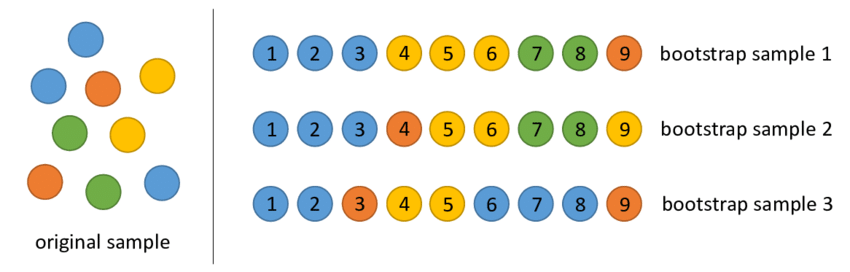

**Procedimiento**

1. Partimos de la muestra original, de tamaño $n$.
2. Extraemos de ella, con reemplazo, una **muestra *bootstrap*** (o remuestra) también de tamaño $n$.
3. Calculamos sobre la remuestra el estadístico de interés: es una **estimación *bootstrap***.
4. Repetimos los pasos 2 y 3 muchas veces (normalmente entre 1000 y 10 000).

El histograma de las estimaciones *bootstrap* (la **distribución *bootstrap***) aproxima la distribución muestral del estadístico, y su desviación estándar es una estimación de su **error estándar**. Lo mejor es que el procedimiento es el mismo para **cualquier estadístico**.

### 4.1 Ejemplo: error estándar de la media

Usamos **solo** la muestra de 1000 observaciones de la sección 3.2, como haríamos en un problema real, y comparamos el resultado con lo que ya sabemos.

In [8]:
def bootstrap(datos, estadistico, n_boot=10_000):
    # Devuelve n_boot estimaciones bootstrap del estadístico calculado sobre los datos
    datos = np.asarray(datos)
    return np.array([estadistico(rng.choice(datos, size=len(datos)))   # remuestra con reemplazo
                     for _ in range(n_boot)])


medias_boot = bootstrap(muestra, np.mean)

print(f'Media de la muestra original:      {muestra.mean():.3f}')
print(f'SE bootstrap:                      {medias_boot.std():.4f}')
print(f'SE con la fórmula (s/√n):          {se_estimado:.4f}')
print(f'SE "verdadero" (simulación, 3.2):  {se_simulado:.4f}')

Media de la muestra original:      38.478
SE bootstrap:                      0.0926
SE con la fórmula (s/√n):          0.0935
SE "verdadero" (simulación, 3.2):  0.0877


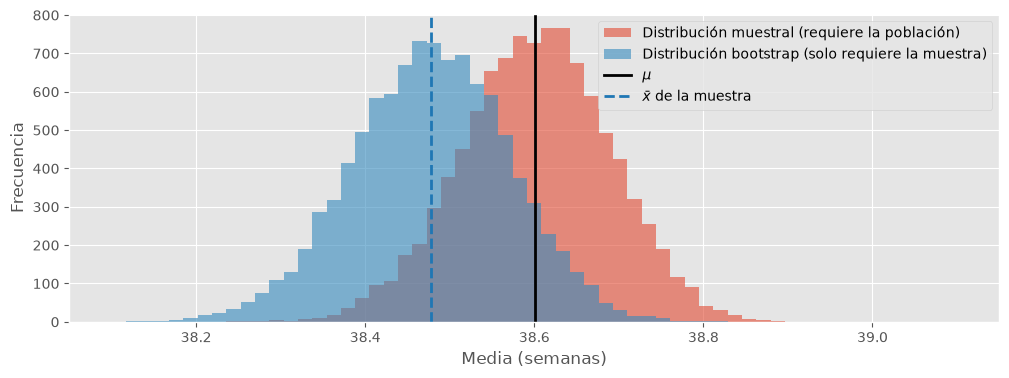

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
bins = np.linspace(38.1, 39.1, 60)
ax.hist(medias, bins=bins, alpha=0.6, label='Distribución muestral (requiere la población)')
ax.hist(medias_boot, bins=bins, alpha=0.6, label='Distribución bootstrap (solo requiere la muestra)')
ax.axvline(mu, color='black', lw=2, label='$\\mu$')
ax.axvline(muestra.mean(), color='tab:blue', lw=2, ls='--', label='$\\bar{x}$ de la muestra')
ax.set_xlabel('Media (semanas)')
ax.set_ylabel('Frecuencia')
ax.legend()
plt.show()

Las dos distribuciones tienen prácticamente **la misma anchura**, que es lo que queremos estimar. Fíjate en que la distribución *bootstrap* está centrada en la media de *nuestra* muestra, no en $\mu$: el *bootstrap* no corrige la estimación puntual, sino que **cuantifica su incertidumbre**.

### 4.2 Ejemplo: error estándar de la desviación estándar

Para la desviación estándar no tenemos una fórmula sencilla del error estándar, pero con el *bootstrap* basta con cambiar la función que calcula el estadístico:

Desviación estándar de la muestra:  2.956 semanas
SE bootstrap de la desv. estándar:  0.269 semanas


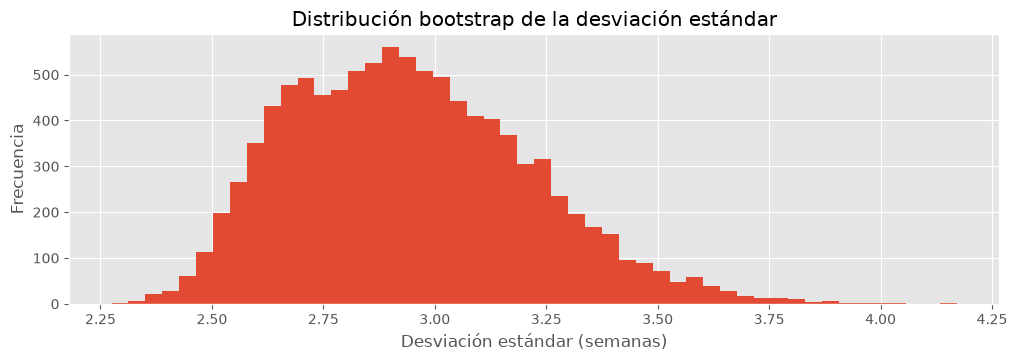

In [10]:
std_boot = bootstrap(muestra, lambda x: x.std(ddof=1))

print(f'Desviación estándar de la muestra:  {muestra.std(ddof=1):.3f} semanas')
print(f'SE bootstrap de la desv. estándar:  {std_boot.std():.3f} semanas')

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.hist(std_boot, bins=50)
ax.set_xlabel('Desviación estándar (semanas)')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución bootstrap de la desviación estándar')
plt.show()

A diferencia de la de la media, esta distribución es **asimétrica**: la desviación estándar es muy sensible a los pocos valores extremos (partos muy prematuros), y su valor depende mucho de cuántos de ellos entran en cada remuestra. El *bootstrap* recoge esta forma sin necesidad de ninguna fórmula, cosa que una aproximación normal no haría.

## 5. Ejercicio: accidentes de tráfico en Barcelona

Usaremos el registro de accidentes de tráfico gestionados por la Guardia Urbana de Barcelona en 2013, publicado en [Open Data BCN](https://opendata-ajuntament.barcelona.cat/), el portal de datos abiertos del Ayuntamiento. Cada fila es un accidente e incluye, entre otros campos, el día de la semana (`Descripció dia setmana`), la hora (`Hora de dia`), la calle (`Nom carrer`) y el número de muertos (`Número de morts`) y de heridos (`Número de lesionats lleus`, `Número de lesionats greus`).

Este conjunto de datos será nuestra **población**: todos los accidentes registrados en Barcelona en 2013. La variable de interés es el **número de accidentes por día**.

In [11]:
datos = pd.read_csv('files/ACCIDENTS_GU_BCN_2013.csv', encoding='latin-1')
print(f'{len(datos)} accidentes registrados')
print(datos.columns.tolist())

9457 accidentes registrados
["Número d'expedient", 'Codi districte', 'Nom districte', 'NK barri', 'Nom barri', 'Codi carrer', 'Nom carrer', 'Num postal caption', 'Descripció dia setmana', 'Dia de setmana', 'Descripció tipus dia', 'NK Any', 'Mes de any', 'Nom mes', 'Dia de mes', 'Hora de dia', 'Descripció torn', 'Descripció causa vianant', 'Número de morts', 'Número de lesionats lleus', 'Número de lesionats greus', 'Número de víctimes', 'Número de vehicles implicats', 'Coordenada UTM (Y)', 'Coordenada UTM (X)']


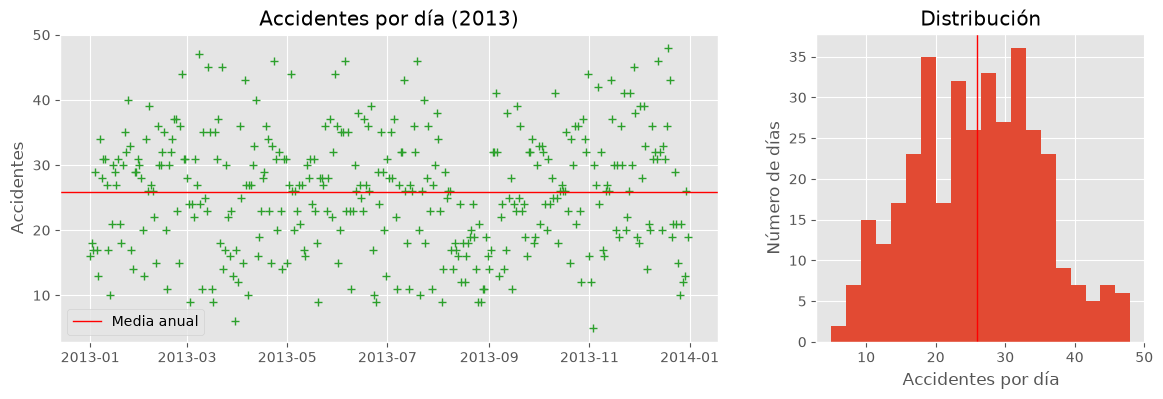

In [12]:
# Fecha de cada accidente y número de accidentes de cada día del año
datos['Fecha'] = pd.to_datetime(dict(year=datos['NK Any'], month=datos['Mes de any'], day=datos['Dia de mes']))
accidentes = datos.groupby('Fecha').size()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [2, 1]})
ax1.plot(accidentes.index, accidentes.to_numpy(), '+', color='tab:green')
ax1.axhline(accidentes.mean(), color='red', lw=1, label='Media anual')
ax1.set_ylabel('Accidentes')
ax1.set_title('Accidentes por día (2013)')
ax1.legend()

ax2.hist(accidentes, bins=20)
ax2.axvline(accidentes.mean(), color='red', lw=1)
ax2.set_xlabel('Accidentes por día')
ax2.set_ylabel('Número de días')
ax2.set_title('Distribución')
plt.show()

Como tenemos toda la población, el **parámetro** (la tasa media de accidentes diarios de 2013) se calcula directamente: el total de accidentes dividido entre 365 días.

In [13]:
print(f'Tasa media poblacional: {accidentes.mean():.2f} accidentes/día')

Tasa media poblacional: 25.91 accidentes/día


Supongamos ahora que solo tenemos acceso a una **muestra**: el número de accidentes de 200 días elegidos al azar (con reemplazo, para que las observaciones sean independientes).

In [14]:
muestra_acc = accidentes.sample(n=200, replace=True, random_state=1)
muestra_acc.head()

Fecha
2013-02-07    27
2013-08-24    14
2013-03-14    45
2013-09-13    25
2013-07-23    40
dtype: int64

**Ejercicio 1**

a) A partir de `muestra_acc`, estima la tasa media de accidentes con un estimador puntual y calcula su error estándar con la fórmula $s/\sqrt{n}$.

In [15]:
# Escribe aquí tu solución

b) Estima el error estándar de la media mediante *bootstrap* (puedes reutilizar la función `bootstrap`). Compara los resultados de a) y b) con la media poblacional.

In [16]:
# Escribe aquí tu solución

## 6. Intervalos de confianza o como comunicar la incertidumbre

### 6.1 De un valor a un rango de valores plausibles

Una estimación puntual proporciona *un único valor plausible* para el parámetro, pero casi siempre contiene cierto error. Al comunicar resultados, es más informativo acompañarla de un **intervalo de confianza** (IC): el valor puntual no es el valor verdadero ni tiene un estatus especial; es solo el resultado de aplicar un estimador a esta muestra. 

El intervalo muestra un rango de valores compatibles con los datos y hace visible la incertidumbre. No garantiza que el parámetro esté dentro de este intervalo concreto: la interpretación del nivel de confianza se refiere al procedimiento y a lo que ocurriría al repetir el muestreo (véase 6.3).

El intervalo suele construirse alrededor de la estimación puntual, y su anchura depende del error estándar.

### 6.2 Construcción

Según el TCL (sección 3.3), en el 95 % de las muestras la media muestral está a menos de $1{,}96\,SE$ de $\mu$. Dicho al revés: en el 95 % de las muestras, **$\mu$ está a menos de $1{,}96\,SE$ de $\bar{x}$**. De ahí el intervalo:

$$ IC_{95\%} = \left[\ \bar{x} - 1{,}96 \cdot SE,\ \ \bar{x} + 1{,}96 \cdot SE\ \right] $$

En general, si la estimación puntual sigue aproximadamente una distribución normal:

$$ \text{estimación puntual} \pm z \cdot SE $$

donde $z$ depende del **nivel de confianza** elegido (se obtiene de la normal estándar; por ejemplo, `stats.norm.ppf(0.975)` = 1,96):

| Nivel de confianza | $z$ |
|:---:|:---:|
| 90 % | 1,645 |
| 95 % | 1,96 |
| 99 % | 2,58 |
| 99,9 % | 3,29 |

Más confianza implica un intervalo **más ancho**: ganamos seguridad a costa de precisión.

### 6.3 ¿Qué significa «95 % de confianza»?

La interpretación correcta es frecuentista, es decir, se refiere a la repetición del muestreo:

> Si tomáramos muchas muestras y construyéramos un IC con cada una, aproximadamente el **95 % de esos intervalos contendría el parámetro verdadero**.

El 95 % es una propiedad del **procedimiento**, no de un intervalo concreto. Una vez calculado, un intervalo contiene $\mu$ o no la contiene: $\mu$ es fijo y no es objeto de afirmaciones probabilísticas. Por eso, aunque coloquialmente se diga que «tenemos un 95 % de confianza», **no es correcto decir que hay un 95 % de probabilidad de que $\mu$ esté en *este* intervalo**.

Lo vemos con una simulación (de nuevo, los primeros hijos hacen de población): construimos 100 intervalos a partir de 100 muestras distintas.

96 de 100 intervalos contienen la media poblacional


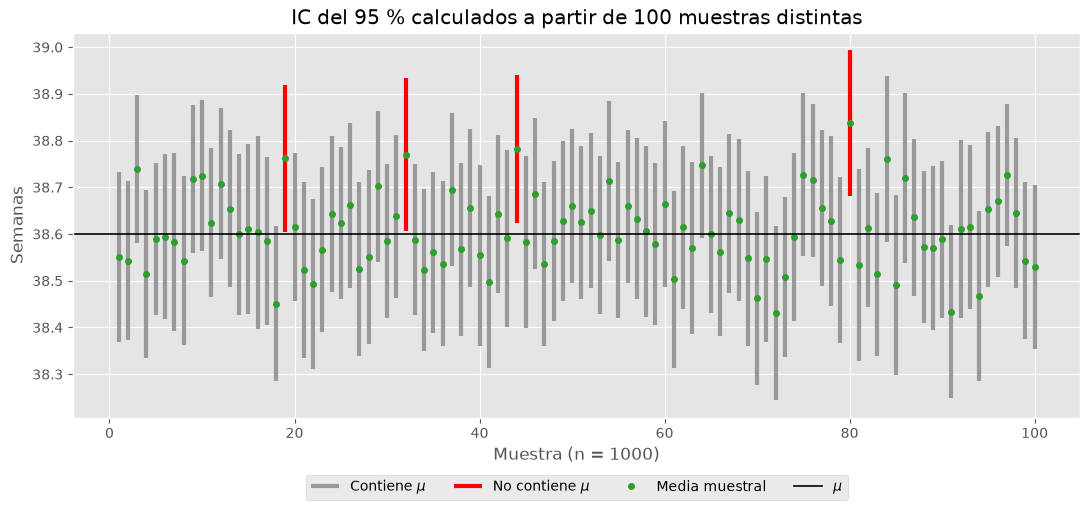

In [17]:
n_intervalos = 100
ic = np.empty((n_intervalos, 2))
medias_ic = np.empty(n_intervalos)

for i in range(n_intervalos):
    m_i = rng.choice(poblacion, size=n)
    se_i = m_i.std(ddof=1) / np.sqrt(n)
    medias_ic[i] = m_i.mean()
    ic[i] = [medias_ic[i] - 1.96 * se_i, medias_ic[i] + 1.96 * se_i]

contiene = (ic[:, 0] <= mu) & (mu <= ic[:, 1])
print(f'{contiene.sum()} de {n_intervalos} intervalos contienen la media poblacional')

idx = np.arange(1, n_intervalos + 1)
fig, ax = plt.subplots(figsize=(13, 5))
ax.vlines(idx[contiene], ic[contiene, 0], ic[contiene, 1], color='0.6', lw=3, label='Contiene $\\mu$')
ax.vlines(idx[~contiene], ic[~contiene, 0], ic[~contiene, 1], color='red', lw=3, label='No contiene $\\mu$')
ax.plot(idx, medias_ic, '.', color='tab:green', ms=8, label='Media muestral')
ax.axhline(mu, color='black', lw=1.2, label='$\\mu$')
ax.set_title('IC del 95 % calculados a partir de 100 muestras distintas')
ax.set_xlabel(f'Muestra (n = {n})')
ax.set_ylabel('Semanas')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=4)
plt.show()

### 6.4 Intervalos de confianza con los datos reales

Volvamos a la situación real: la NSFG es **una muestra** de todos los nacimientos de EE. UU. y no tenemos otra. Calculamos el IC del 95 % de la duración media del embarazo en cada grupo:

,media,SE,IC 95 % inf.,IC 95 % sup.
Primeros hijos,38.601,0.042,38.519,38.683
Demás hijos,38.523,0.038,38.448,38.597


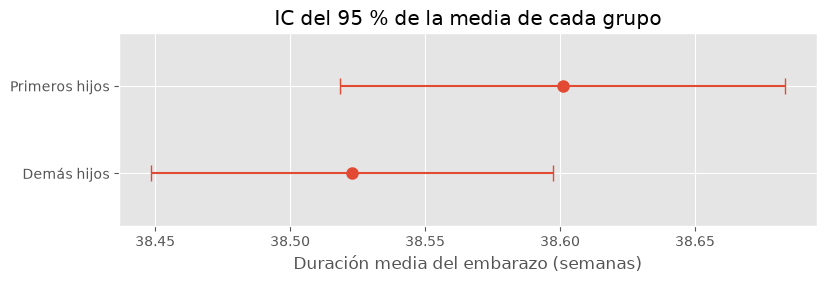

In [18]:
def ic_media(x, z=1.96):
    # IC de la media basado en la aproximación normal (TCL)
    media = np.mean(x)
    se = np.std(x, ddof=1) / np.sqrt(len(x))
    return media, se, media - z * se, media + z * se


tabla_ic = pd.DataFrame([ic_media(primeros), ic_media(otros)],
                        index=['Primeros hijos', 'Demás hijos'],
                        columns=['media', 'SE', 'IC 95 % inf.', 'IC 95 % sup.'])
display(tabla_ic.round(3))

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.errorbar(tabla_ic['media'], [1, 0], xerr=1.96 * tabla_ic['SE'], fmt='o', ms=8, capsize=6)
ax.set_yticks([1, 0], tabla_ic.index)
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel('Duración media del embarazo (semanas)')
ax.set_title('IC del 95 % de la media de cada grupo')
plt.show()

Los dos intervalos se solapan ampliamente: los datos son compatibles con que ambos grupos tengan la misma media. Aun así, comparar visualmente dos intervalos no es una prueba formal; para eso necesitamos un **contraste de hipótesis** (sección 7).

### 6.5 Intervalos de confianza *bootstrap*

Si el estadístico no tiene una fórmula para el error estándar, podemos obtener el IC directamente de la distribución *bootstrap*: el IC del 95 % está formado por los **percentiles 2,5 y 97,5** de las estimaciones *bootstrap* (*método de los percentiles*). Usamos las distribuciones de la sección 4, calculadas sobre la muestra de 1000 observaciones:

In [19]:
_, _, inf, sup = ic_media(muestra)
ic_boot_media = np.percentile(medias_boot, [2.5, 97.5])
ic_boot_std = np.percentile(std_boot, [2.5, 97.5])

print(f'IC 95 % de la media (fórmula):               [{inf:.3f}, {sup:.3f}]')
print(f'IC 95 % de la media (bootstrap):             [{ic_boot_media[0]:.3f}, {ic_boot_media[1]:.3f}]')
print(f'IC 95 % de la desv. estándar (bootstrap):    [{ic_boot_std[0]:.3f}, {ic_boot_std[1]:.3f}]')

IC 95 % de la media (fórmula):               [38.295, 38.661]
IC 95 % de la media (bootstrap):             [38.292, 38.655]
IC 95 % de la desv. estándar (bootstrap):    [2.505, 3.523]


**Ejercicio 2**

Con la muestra `muestra_acc` del ejercicio 1, calcula el IC del 95 % de la tasa media de accidentes a) con la fórmula y b) con el método de los percentiles *bootstrap*. ¿Contienen la media poblacional?

In [20]:
# Escribe aquí tu solución

## 7. Contraste de hipótesis y significación estadística

Volvemos a la pregunta inicial: el resultado, ¿es **estadísticamente significativo**? El procedimiento para responderla se llama **contraste de hipótesis**.

### 7.1 Hipótesis nula e hipótesis alternativa

Un contraste empieza reduciendo la pregunta a dos hipótesis contrapuestas:

+ $H_0$, **hipótesis nula**: no hay efecto. La duración media del embarazo es la misma en los dos grupos ($\mu_1 = \mu_2$); «primeros hijos» y «demás hijos» son muestras de una misma población y la diferencia observada se debe al azar del muestreo. Representa la **postura escéptica**.
+ $H_A$, **hipótesis alternativa**: el efecto es real ($\mu_1 \neq \mu_2$).

La regla del contraste es asumir $H_0$ y **rechazarla solo si los datos observados son muy poco plausibles bajo ella**. Si no lo son, **no rechazamos** $H_0$, lo cual no equivale a demostrar que sea cierta: la ausencia de evidencia no es evidencia de ausencia.

### 7.2 El valor *p*

> El **valor *p*** es la probabilidad de obtener, **suponiendo que $H_0$ es cierta**, un resultado al menos tan extremo (tan favorable a $H_A$) como el observado.

+ Un valor *p* **pequeño** indica que el resultado sería raro si $H_0$ fuera cierta: es evidencia en contra de $H_0$.
+ Un valor *p* **grande** indica que el resultado es perfectamente compatible con el azar.

Para decidir se fija **de antemano** un umbral $\alpha$, el **nivel de significación**, normalmente $\alpha = 0{,}05$. Si $p < \alpha$, rechazamos $H_0$ y decimos que el resultado es **estadísticamente significativo**. La elección del 5 % es una convención, no una verdad científica.

«Extremo» puede entenderse en un solo sentido (**contraste unilateral**) o en ambos (**contraste bilateral**). Si antes de ver los datos no teníamos motivos para esperar un sentido concreto, el contraste debe ser bilateral.

> **Un poco de historia.** La noción moderna de significación estadística la desarrolló R. A. Fisher en la década de 1920, cuando buscaba una forma de decidir si las variaciones en el rendimiento de los cultivos se debían a un fertilizante o a factores aleatorios. Supuso que el fertilizante no tenía ningún efecto (la hipótesis nula) y calculó la probabilidad de obtener, aun así, un rendimiento como el observado: el valor *p*.

### 7.3 El procedimiento en cuatro pasos

1. **Elegir un estadístico de contraste** que cuantifique el efecto. En la NSFG: la diferencia entre las medias de los dos grupos.
2. **Definir un modelo de $H_0$**: cómo se generarían los datos si el efecto no existiera.
3. **Calcular el valor *p***: la probabilidad, bajo ese modelo, de obtener un estadístico tan extremo como el observado. A menudo se obtiene simulando el modelo de $H_0$ muchas veces.
4. **Interpretar el resultado**: si $p < \alpha$, el efecto es estadísticamente significativo; es decir, es poco probable que se deba solo al azar.

Veamos dos ejemplos: uno en el que el modelo de $H_0$ es evidente y otro en el que hay que construirlo a partir de los datos.

### 7.4 Ejemplo 1: ¿está sesgada esta moneda?

El viernes 4 de enero de 2002 apareció esta afirmación estadística en *The Guardian*:

> Al hacer girar una moneda belga de un euro sobre su canto 250 veces, salió cara 140 veces y cruz 110. «Me parece muy sospechoso», dijo Barry Blight, profesor de estadística de la London School of Economics. «Si la moneda no estuviera sesgada, la probabilidad de obtener un resultado tan extremo como ese sería inferior al 7 %».

Apliquemos los cuatro pasos:

1. **Estadístico**: la proporción de caras, que en el experimento es $140/250 = 0{,}56$.
2. **Modelo de $H_0$**: la moneda es equilibrada ($p = 0{,}5$). Sabemos simular exactamente este modelo: 250 lanzamientos de una moneda equilibrada.
3. **Valor *p***: simulamos 100 000 experimentos y contamos qué fracción es al menos tan extrema como la observada.

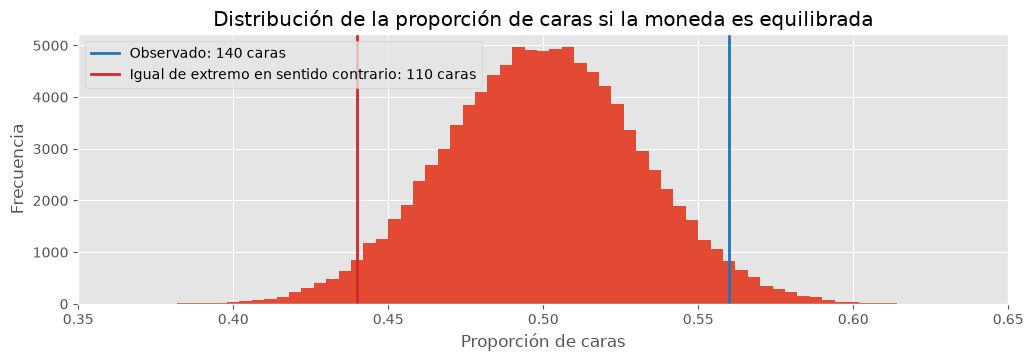

In [26]:
n_lanz = 250
caras_obs = 140

# Modelo de H0: 100 000 experimentos de 250 lanzamientos de una moneda equilibrada
caras_h0 = rng.binomial(n_lanz, 0.5, size=100000)

fig, ax = plt.subplots(figsize=(12, 3.5))
bins = (np.arange(n_lanz + 2) - 0.5) / n_lanz
ax.hist(caras_h0 / n_lanz, bins=bins)
ax.axvline(caras_obs / n_lanz, color='tab:blue', lw=2, label='Observado: 140 caras')
ax.axvline((n_lanz - caras_obs) / n_lanz, color='tab:red', lw=2, label='Igual de extremo en sentido contrario: 110 caras')
ax.set_xlim(0.35, 0.65)
ax.set_xlabel('Proporción de caras')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución de la proporción de caras si la moneda es equilibrada')
ax.legend()
plt.show()

In [27]:
p_unilateral = np.mean(caras_h0 >= caras_obs)
p_bilateral = np.mean(np.abs(caras_h0 - n_lanz / 2) >= abs(caras_obs - n_lanz / 2))

print(f'Valor p unilateral (≥ 140 caras):          {p_unilateral:.3f}')
print(f'Valor p bilateral  (≥ 140 o ≤ 110 caras):  {p_bilateral:.3f}')
print(f'Comprobación con el test binomial exacto:  {stats.binomtest(caras_obs, n_lanz, 0.5).pvalue:.3f}')

Valor p unilateral (≥ 140 caras):          0.033
Valor p bilateral  (≥ 140 o ≤ 110 caras):  0.067
Comprobación con el test binomial exacto:  0.066


4. **Interpretación**: si la moneda es equilibrada, un resultado tan desequilibrado como 140/250 (en cualquiera de los dos sentidos) aparece en torno al 7 % de las veces; el «inferior al 7 %» del profesor es el valor *p* bilateral. Como no había ningún motivo previo para sospechar que la moneda favoreciera las caras, el contraste adecuado es el bilateral y, con $\alpha = 0{,}05$, **no rechazamos $H_0$**: los datos no bastan para concluir que la moneda esté sesgada. Otra persona, con otro umbral, podría llegar a otra conclusión; por eso conviene fijar $\alpha$ antes de ver los datos.

### 7.5 Ejemplo 2: test de permutaciones para la NSFG

En la NSFG no tenemos un modelo evidente para $H_0$, como la binomial de la moneda. Pero podemos construirlo a partir de los datos: **si $H_0$ es cierta, la etiqueta «primer hijo» / «demás hijos» no importa**, porque todas las duraciones provienen de la misma población. Por tanto, podemos:

1. Juntar los dos grupos en un único conjunto.
2. Repartir los valores al azar en dos grupos del mismo tamaño que los originales (**permutar las etiquetas**).
3. Calcular la diferencia de medias entre esos dos grupos.

Repitiendo el proceso muchas veces obtenemos la distribución de la diferencia de medias **bajo $H_0$**. El valor *p* es la proporción de permutaciones en las que la diferencia es, en valor absoluto, igual o mayor que la observada (contraste bilateral).

Para empezar, comparemos las dos distribuciones:

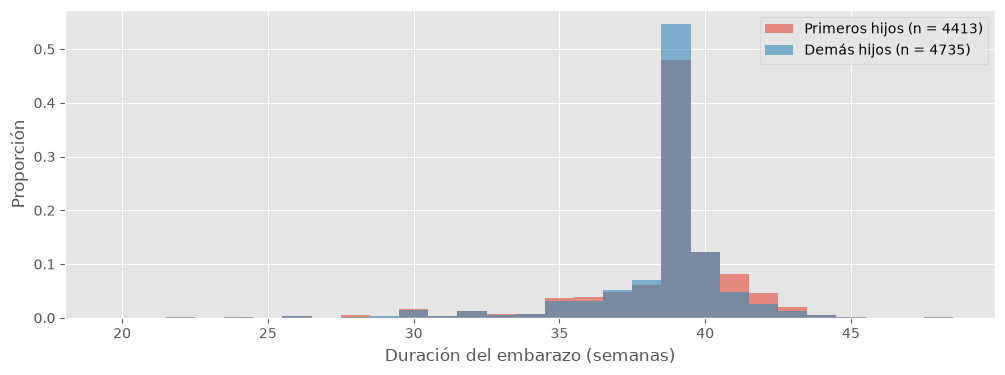

In [23]:
x = primeros.to_numpy()
y = otros.to_numpy()
n1, n2 = len(x), len(y)

fig, ax = plt.subplots(figsize=(12, 4))
bins = np.arange(20, 50) - 0.5
ax.hist(x, bins=bins, density=True, alpha=0.6, label=f'Primeros hijos (n = {n1})')
ax.hist(y, bins=bins, density=True, alpha=0.6, label=f'Demás hijos (n = {n2})')
ax.set_xlabel('Duración del embarazo (semanas)')
ax.set_ylabel('Proporción')
ax.legend()
plt.show()

Son muy parecidas; en los primeros hijos hay algo menos de partos a las 39 semanas y algo más de partos tardíos (41-43 semanas). La pregunta es si estas diferencias son mayores de lo que cabría esperar por azar.

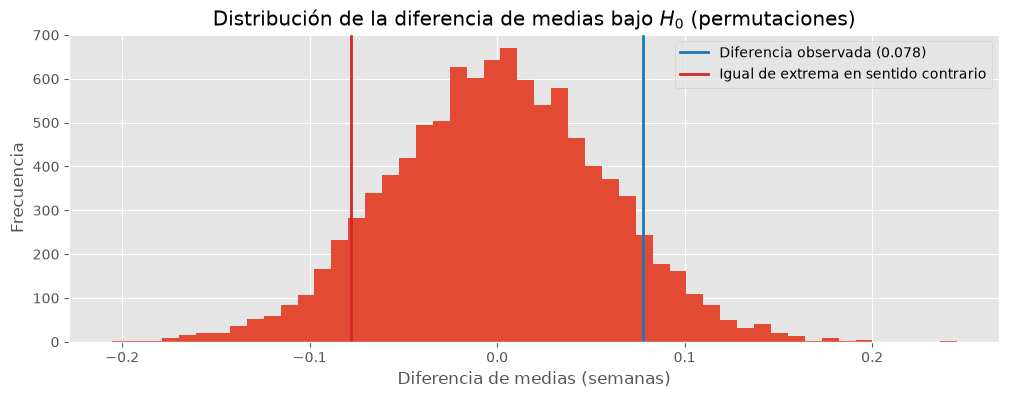

Valor p (permutaciones, bilateral): 0.170


In [24]:
conjunto = np.concatenate([x, y])     # bajo H0, todos los valores vienen de la misma población

n_perm = 10_000
dif_h0 = np.empty(n_perm)
for i in range(n_perm):
    perm = rng.permutation(conjunto)                    # reasignamos las etiquetas al azar
    dif_h0[i] = perm[:n1].mean() - perm[n1:].mean()

p_valor = np.mean(np.abs(dif_h0) >= abs(diferencia_obs))

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(dif_h0, bins=50)
ax.axvline(diferencia_obs, color='tab:blue', lw=2, label=f'Diferencia observada ({diferencia_obs:.3f})')
ax.axvline(-diferencia_obs, color='tab:red', lw=2, label='Igual de extrema en sentido contrario')
ax.set_xlabel('Diferencia de medias (semanas)')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución de la diferencia de medias bajo $H_0$ (permutaciones)')
ax.legend()
plt.show()

print(f'Valor p (permutaciones, bilateral): {p_valor:.3f}')

**Interpretación.** Si la duración del embarazo no dependiera del orden de nacimiento, una diferencia tan grande como la observada aparecería en torno al 17 % de los repartos al azar. Con $\alpha = 0{,}05$, **no rechazamos $H_0$**: la diferencia no es estadísticamente significativa. Esto no demuestra que la diferencia sea cero, sino que **con estos datos no podemos distinguirla del azar**.

### 7.6 Alternativa analítica: el error estándar de la diferencia

Para la diferencia de dos medias existe una fórmula que nos permite evitar la simulación. El error estándar de la diferencia entre dos medias muestrales independientes se obtiene a partir de los errores estándar de cada una:

$$ SE_{\bar{x}_1 - \bar{x}_2} = \sqrt{SE_{\bar{x}_1}^2 + SE_{\bar{x}_2}^2} = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}} $$

Con él podemos:

+ construir el **IC del 95 % de la diferencia**: $(\bar{x}_1 - \bar{x}_2) \pm 1{,}96 \cdot SE_{\bar{x}_1 - \bar{x}_2}$;
+ calcular el **valor *p*** a partir de $z = (\bar{x}_1 - \bar{x}_2) / SE_{\bar{x}_1 - \bar{x}_2}$, que bajo $H_0$ sigue aproximadamente una normal estándar. Es lo que hace (con la distribución *t* en lugar de la normal) el **test *t* de Welch**, disponible en `scipy.stats.ttest_ind`.

In [25]:
se_dif = np.sqrt(x.var(ddof=1) / n1 + y.var(ddof=1) / n2)
z_obs = diferencia_obs / se_dif
ic_dif = (diferencia_obs - 1.96 * se_dif, diferencia_obs + 1.96 * se_dif)

print(f'Diferencia observada:            {diferencia_obs:.3f} semanas')
print(f'SE de la diferencia:             {se_dif:.3f} semanas')
print(f'IC 95 % de la diferencia:        [{ic_dif[0]:.3f}, {ic_dif[1]:.3f}] semanas')
print()
print(f'Valor p (aproximación normal):   {2 * stats.norm.sf(abs(z_obs)):.3f}')
print(f'Valor p (test t de Welch):       {stats.ttest_ind(x, y, equal_var=False).pvalue:.3f}')
print(f'Valor p (permutaciones, 7.5):    {p_valor:.3f}')

Diferencia observada:            0.078 semanas
SE de la diferencia:             0.057 semanas
IC 95 % de la diferencia:        [-0.033, 0.189] semanas

Valor p (aproximación normal):   0.168
Valor p (test t de Welch):       0.169
Valor p (permutaciones, 7.5):    0.170


Los tres métodos dan prácticamente el mismo valor *p*. Además, el IC del 95 % de la diferencia **incluye el 0**, lo que es otra forma de decir lo mismo: un IC del 95 % contiene el 0 exactamente cuando el contraste bilateral correspondiente (calculado con el mismo error estándar) da $p > 0{,}05$. **Intervalos de confianza y contrastes son dos caras de la misma moneda.**

### 7.7 Los contrastes no son infalibles: errores de tipo I y II

Un contraste de hipótesis puede llevarnos a una decisión equivocada de dos maneras:

| | $H_0$ es cierta | $H_0$ es falsa |
|---|:---:|:---:|
| **Rechazamos $H_0$** | Error de tipo I (falso positivo) | Decisión correcta |
| **No rechazamos $H_0$** | Decisión correcta | Error de tipo II (falso negativo) |

El nivel de significación $\alpha$ es precisamente la probabilidad de cometer un **error de tipo I** que estamos dispuestos a aceptar: con $\alpha = 0{,}05$, si $H_0$ es cierta, la rechazaremos por error en un 5 % de los casos. Reducir $\alpha$ disminuye los falsos positivos, pero aumenta los falsos negativos.

### 7.8 Cómo (no) interpretar un valor *p*

+ **Un valor *p* bajo no dice por qué lo es.** Si $p < 0{,}05$, caben dos explicaciones: el efecto es real o ha ocurrido una casualidad poco probable. El contraste no permite saber cuál es la correcta.
+ **$P(E \mid H_0) \neq P(H_0 \mid E)$.** El valor *p* es la probabilidad de los datos suponiendo $H_0$, no la probabilidad de que $H_0$ sea cierta. Un $p = 0{,}03$ **no** significa que haya un 3 % de probabilidad de que el efecto se deba al azar, ni un 97 % de que sea real.
+ **Significativo no es lo mismo que relevante.** Con muestras muy grandes, efectos minúsculos resultan estadísticamente significativos. Hay que fijarse siempre en el **tamaño del efecto** (y en su IC). En la NSFG, aunque la diferencia fuera significativa, 0,08 semanas son unas 13 horas: una diferencia sin importancia práctica.
+ **El umbral del 5 % es arbitrario**, y el valor *p* depende del estadístico y del modelo de $H_0$ elegidos. Conviene leerlo como un orden de magnitud: por debajo del 1 %, es poco probable que el efecto se deba al azar; por encima del 10 %, el azar lo explica de forma plausible; entre el 1 % y el 10 %, la evidencia es dudosa.

> **Para leer:** R. Nuzzo, [«Scientific method: Statistical errors»](https://www.nature.com/articles/506150a), *Nature* 506, 150-152 (13 de febrero de 2014).
>
> El artículo relata el caso de un investigador que creyó haber encontrado pruebas de que las personas con ideas políticas extremas perciben el mundo, literalmente, más en blanco y negro que las moderadas (distinguían peor los tonos de gris). Los datos iniciales respaldaban la hipótesis, con un valor *p* de 0,01. Antes de publicar, repitió el estudio con datos nuevos: el valor *p* fue de 0,59 y el efecto desapareció.

## 8. Conclusiones

### Resumen de la inferencia frecuentista

+ Las **estimaciones puntuales** son el punto de partida y sirven para formular hipótesis.
+ Su variabilidad se mide con el **error estándar**, que se obtiene con una fórmula (la media, la diferencia de medias) o mediante ***bootstrap*** (cualquier estadístico).
+ La incertidumbre se comunica con **intervalos de confianza**, cuyo nivel (p. ej., 95 %) se refiere al procedimiento, no a un intervalo concreto.
+ Para decidir si un efecto es real, fijamos $\alpha$ de antemano y calculamos el valor *p*, $P(\text{datos al menos tan extremos} \mid H_0)$:
    + si $p < \alpha$, **rechazamos $H_0$**: el resultado es estadísticamente significativo;
    + si $p \geq \alpha$, **no rechazamos $H_0$** (lo que no equivale a aceptarla).

### Respuestas a las preguntas iniciales

1. **¿Puede deberse al azar?** Sí. Si no hubiera ninguna diferencia real, una diferencia como la observada aparecería en torno al 17 % de las veces.
2. **¿Es estadísticamente significativa?** No: $p \approx 0{,}17 > 0{,}05$, y el IC del 95 % de la diferencia incluye el 0.
3. **¿Es relevante?** Tampoco: incluso si fuera real, una diferencia de unas 13 horas en la duración del embarazo carece de importancia práctica.

### Reflexión final: datos, azar y escepticismo

**¿Los macrodatos aceleran la investigación médica?** Muchas asociaciones en datos de salud detectadas al explorar grandes bases de datos no se confirmaron después en experimentos controlados. Entre las causas están los errores en los datos y el **problema de las comparaciones múltiples**: si se buscan suficientes patrones, algunos aparecerán por azar con un valor *p* convincente (con $\alpha = 0{,}05$, en promedio uno de cada veinte contrastes de efectos inexistentes saldrá «significativo»). Los macrodatos ofrecen grandes oportunidades, pero requieren métodos estadísticos adecuados y un diseño de estudio sólido.

**La postura escéptica.** Por muchos datos que tengamos, seguimos dependiendo de nuestro criterio para interpretarlos, explicarlos y utilizarlos. Los datos no hablan por sí mismos: los científicos de datos los interpretan y proponen una narrativa útil derivada de ellos, si es que existe. Y sesgos cognitivos como el **sesgo de confirmación** o el **sesgo narrativo** distorsionan esa interpretación. La hipótesis nula es, en el fondo, una forma sistemática de ser escépticos con nuestras propias conclusiones.